# arXiv AI/ML Research Abstracts: NLP Analysis

Exploratory text analysis of 7,701 arXiv AI/ML abstracts (27 Sep 2025 – 29 Apr 2026): cleaning, term frequency, TF-IDF, LDA, sentence embeddings with k-means, BERTopic, and regex-based theme / model-family / method prevalence with monthly coverage checks.

- **Data:** [arXiv AI/ML Research Papers 2025-2026 (Kaggle, `shree0910`)](https://www.kaggle.com/datasets/shree0910/arxiv-aiml-research-papers-20252026). Download `arxiv_ai_ml_papers.csv` and set `FILE_PATH` in the first code cell if it is not found automatically.
- **Environment:** see `requirements.txt` (embeddings and BERTopic need `sentence-transformers` and `bertopic`).
- **Read before interpreting:** 78% of the records are from April 2026 and only 25 are from September 2025 (see section 14 monthly coverage), so month-to-month comparisons are descriptive only. The README lists further known limitations.

# 1. Setup and reproducibility

In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
FILE_NAME = "arxiv_ai_ml_papers.csv"
FILE_PATH = None  # Optional: set to the full path if auto-detection does not find the CSV

candidate_paths = []
if FILE_PATH:
    candidate_paths.append(Path(FILE_PATH))
candidate_paths += [
    Path("/kaggle/input/datasets/shree0910/arxiv-aiml-research-papers-20252026/arxiv_ai_ml_papers.csv"),
    Path("/kaggle/input/arxiv-aiml-research-papers-20252026/arxiv_ai_ml_papers.csv"),
    Path.cwd() / FILE_NAME,
    Path("/mnt/data") / FILE_NAME,
]

file_path = next((p for p in candidate_paths if p.exists()), None)
if file_path is None:
    raise FileNotFoundError(
        f"Could not find {FILE_NAME}. Set FILE_PATH to the actual CSV path. "
        "In Kaggle, confirm the dataset is added under Notebook > Add Input."
    )

print(f"Loading: {file_path}")
df_raw = pd.read_csv(file_path, low_memory=False)
df = df_raw.copy()
print(f"Raw shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
display(df.head())

Loading: /mnt/d/1-ML_and_data_science/8-arxive_Al_ML_papers_abstracts_analysis/arxiv_ai_ml_papers.csv
Raw shape: 7,701 rows × 26 columns


,paper_id,title,authors,num_authors,first_author,abstract,abstract_length,word_count,primary_category,all_categories,...,journal_ref,comment,has_doi,doi,arxiv_url,pdf_url,is_large_collaboration,is_updated,update_lag_days,days_since_submission
0,2604.26951v1,Turning the TIDE: Cross-Architecture Distillat...,Gongbo Zhang; Wen Wang; Ye Tian; Li Yuan,4,Gongbo Zhang,Diffusion large language models (dLLMs) offer ...,1269,167,cs.CL,cs.CL; cs.AI; cs.LG,...,Not Available,"15 pages, 3 figures. Code: https://github.com/...",0,Not Available,https://arxiv.org/abs/2604.26951v1,https://arxiv.org/pdf/2604.26951v1,0,0,0,1
1,2604.26231v1,ProMax: Exploring the Potential of LLM-derived...,Yi Zhang; Yiwen Zhang; Kai Zheng; Tong Chen; H...,5,Yi Zhang,The remarkable text understanding and generati...,1748,233,cs.IR,cs.IR,...,Not Available,"11 pages, 8 figures, accepted by SIGIR 2026",0,Not Available,https://arxiv.org/abs/2604.26231v1,https://arxiv.org/pdf/2604.26231v1,0,0,0,1
2,2604.26567v1,AirZoo: A Unified Large-Scale Dataset for Grou...,Xiaoya Cheng; Rouwan Wu; Xinyi Liu; Zeyu Cui; ...,9,Xiaoya Cheng,Despite the rapid progress in data-driven 3D v...,1692,217,cs.CV,cs.CV,...,Not Available,No comment,0,Not Available,https://arxiv.org/abs/2604.26567v1,https://arxiv.org/pdf/2604.26567v1,0,0,0,1
3,2604.26565v1,"DenseStep2M: A Scalable, Training-Free Pipelin...",Mingji Ge; Qirui Chen; Zeqian Li; Weidi Xie,4,Mingji Ge,Long-term video understanding requires interpr...,1758,204,cs.CV,cs.CV,...,Not Available,No comment,0,Not Available,https://arxiv.org/abs/2604.26565v1,https://arxiv.org/pdf/2604.26565v1,0,0,0,1
4,2604.26520v1,3D-LENS: A 3D Lifting-based Elevated Novel-vie...,William Grolleau; Astrid Sabourin; Guillaume L...,4,William Grolleau,Aerial-Ground Re-Identification (AG-ReID) is c...,1418,174,cs.CV,cs.CV,...,Not Available,No comment,0,Not Available,https://arxiv.org/abs/2604.26520v1,https://arxiv.org/pdf/2604.26520v1,0,0,0,1


# 2 - Understand the dataset
Review column names, types, missingness, and exact duplicates before choosing text fields. The code below prints sample values to make column mapping transparent.

In [2]:
print("Column names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()

missing = (df.isna().sum().rename("missing_count").to_frame())
missing["missing_percent"] = (missing["missing_count"] / max(len(df), 1) * 100).round(2)
display(missing.sort_values("missing_count", ascending=False))

print(f"Exact duplicate rows: {df.duplicated().sum():,}")
for col in df.columns:
    print(f"\n--- {col} ---")
    print(df[col].dropna().astype(str).head(3).tolist())

Column names:
['paper_id', 'title', 'authors', 'num_authors', 'first_author', 'abstract', 'abstract_length', 'word_count', 'primary_category', 'all_categories', 'num_categories', 'submitted_date', 'updated_date', 'year', 'month', 'has_journal_ref', 'journal_ref', 'comment', 'has_doi', 'doi', 'arxiv_url', 'pdf_url', 'is_large_collaboration', 'is_updated', 'update_lag_days', 'days_since_submission']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7701 entries, 0 to 7700
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   paper_id                7701 non-null   object
 1   title                   7701 non-null   object
 2   authors                 7701 non-null   object
 3   num_authors             7701 non-null   int64 
 4   first_author            7701 non-null   object
 5   abstract                7701 non-null   object
 6   abstract_length         7701 non-null 

,missing_count,missing_percent
paper_id,0,0.0
title,0,0.0
update_lag_days,0,0.0
is_updated,0,0.0
is_large_collaboration,0,0.0
pdf_url,0,0.0
arxiv_url,0,0.0
doi,0,0.0
has_doi,0,0.0
comment,0,0.0


Exact duplicate rows: 0

--- paper_id ---
['2604.26951v1', '2604.26231v1', '2604.26567v1']

--- title ---
['Turning the TIDE: Cross-Architecture Distillation for Diffusion Large Language Models', 'ProMax: Exploring the Potential of LLM-derived Profiles with Distribution Shaping for Recommender Systems', 'AirZoo: A Unified Large-Scale Dataset for Grounding Aerial Geometric 3D Vision']

--- authors ---
['Gongbo Zhang; Wen Wang; Ye Tian; Li Yuan', 'Yi Zhang; Yiwen Zhang; Kai Zheng; Tong Chen; Hongzhi Yin', 'Xiaoya Cheng; Rouwan Wu; Xinyi Liu; Zeyu Cui; Yan Liu; Na Zhao; Yu Liu; Maojun Zhang; Shen Yan']

--- num_authors ---
['4', '5', '9']

--- first_author ---
['Gongbo Zhang', 'Yi Zhang', 'Xiaoya Cheng']

--- abstract ---
["Diffusion large language models (dLLMs) offer parallel decoding and bidirectional context, but state-of-the-art dLLMs require billions of parameters for competitive performance. While existing distillation methods for dLLMs reduce inference steps within a single archit

# 3. Detect the title, abstract, and year columns

In [3]:
def normalize_colname(name):
    return re.sub(r"[^a-z0-9]+", "_", str(name).lower()).strip("_")

normalized_columns = {normalize_colname(c): c for c in df.columns}

def choose_column(candidates):
    # Exact normalized alias first, then a conservative substring match
    for alias in candidates:
        if alias in normalized_columns:
            return normalized_columns[alias]
    for norm, original in normalized_columns.items():
        if any(alias in norm for alias in candidates if len(alias) >= 5):
            return original
    return None

ABSTRACT_COL = choose_column(["abstract", "summary", "paper_abstract", "description"])
TITLE_COL = choose_column(["title", "paper_title", "name"])
YEAR_COL = choose_column(["year", "published_year", "publication_year", "published", "date", "created"])

# If needed, replace None or the detected value with an exact column name, e.g.:
# ABSTRACT_COL = "abstract"
# TITLE_COL = "title"
# YEAR_COL = "year"

print("Detected title column:", TITLE_COL)
print("Detected abstract column:", ABSTRACT_COL)
print("Detected year/date column:", YEAR_COL)

if ABSTRACT_COL is None:
    raise ValueError("No abstract-like column detected. Set ABSTRACT_COL to the correct column name.")
if ABSTRACT_COL not in df.columns:
    raise KeyError(f"ABSTRACT_COL={ABSTRACT_COL!r} is not in the dataframe columns.")

Detected title column: title
Detected abstract column: abstract
Detected year/date column: year


# 4. Clean the data and prepare analysis fields

In [4]:
initial_rows = len(df)
df = df.drop_duplicates().copy()
rows_after_exact_dedup = len(df)

# Convert the abstract field to string while keeping missing values missing.
df["abstract_original"] = df[ABSTRACT_COL]
df["abstract_original"] = df["abstract_original"].where(df["abstract_original"].notna(), np.nan)
df = df[df["abstract_original"].notna()].copy()
df["abstract_original"] = df["abstract_original"].astype(str).str.strip()
df = df[df["abstract_original"].str.len() > 0].copy()

def clean_abstract(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\$[^$]*\$", " ", text)  # remove inline LaTeX math blocks when present
    text = re.sub(r"[^a-z0-9\s-]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["abstract_clean"] = df["abstract_original"].map(clean_abstract)
df["word_count"] = df["abstract_clean"].str.split().str.len()
df["char_count"] = df["abstract_original"].str.len()

if TITLE_COL and TITLE_COL in df.columns:
    df["title_analysis"] = df[TITLE_COL].fillna("").astype(str).str.strip()
else:
    df["title_analysis"] = ""

if YEAR_COL and YEAR_COL in df.columns:
    # Supports numeric years and common date strings.
    year_numeric = pd.to_numeric(df[YEAR_COL], errors="coerce")
    date_year = pd.to_datetime(df[YEAR_COL], errors="coerce", utc=True).dt.year
    df["publication_year"] = year_numeric.where(year_numeric.between(1900, 2100), date_year)
else:
    df["publication_year"] = np.nan

print(f"Rows before cleaning: {initial_rows:,}")
print(f"Rows after exact duplicate removal: {rows_after_exact_dedup:,}")
print(f"Rows with usable abstracts: {len(df):,}")
print(f"Rows removed from initial data: {initial_rows - len(df):,}")
display(df[["title_analysis", "abstract_original", "abstract_clean", "word_count", "publication_year"]].head())

Rows before cleaning: 7,701
Rows after exact duplicate removal: 7,701
Rows with usable abstracts: 7,701
Rows removed from initial data: 0


,title_analysis,abstract_original,abstract_clean,word_count,publication_year
0,Turning the TIDE: Cross-Architecture Distillat...,Diffusion large language models (dLLMs) offer ...,diffusion large language models dllms offer pa...,173,2026
1,ProMax: Exploring the Potential of LLM-derived...,The remarkable text understanding and generati...,the remarkable text understanding and generati...,233,2026
2,AirZoo: A Unified Large-Scale Dataset for Grou...,Despite the rapid progress in data-driven 3D v...,despite the rapid progress in data-driven 3d v...,219,2026
3,"DenseStep2M: A Scalable, Training-Free Pipelin...",Long-term video understanding requires interpr...,long-term video understanding requires interpr...,204,2026
4,3D-LENS: A 3D Lifting-based Elevated Novel-vie...,Aerial-Ground Re-Identification (AG-ReID) is c...,aerial-ground re-identification ag-reid is con...,173,2026


# 5. Exploratory data analysis (EDA)

Abstract word-count summary:


,count,mean,std,min,25%,50%,75%,max
word_count,7701.0,180.847033,41.618961,26.0,152.0,180.0,210.0,299.0


Abstracts with fewer than 10 words: 0
Abstracts with fewer than 30 words: 1


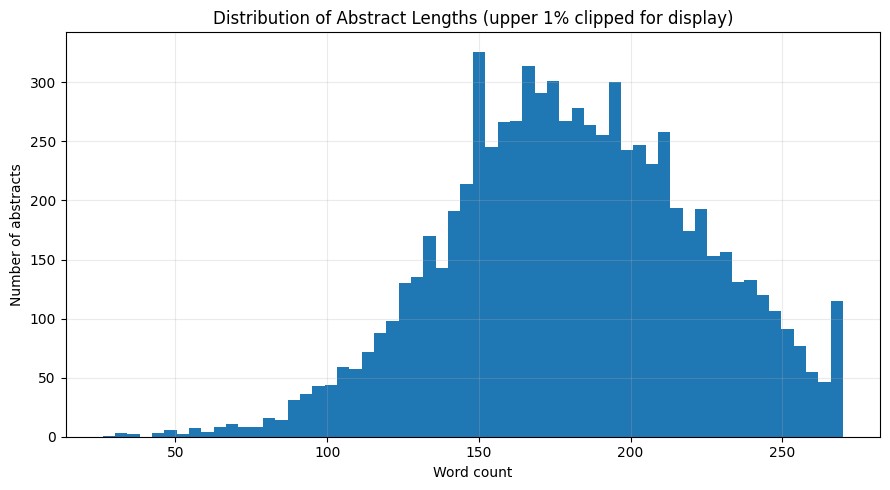

Year coverage: 2025–2026; rows with year: 7,701


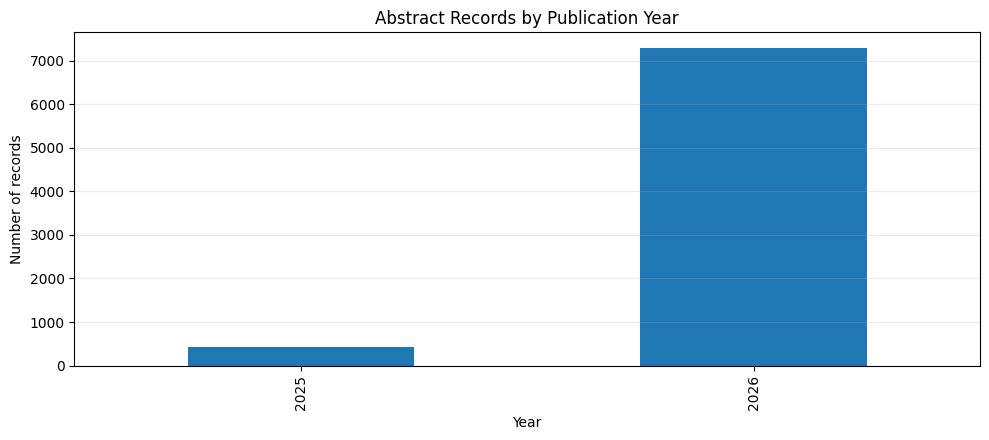

In [5]:
if df.empty:
    raise ValueError("No usable abstracts remain after cleaning. Check the selected abstract column.")

print("Abstract word-count summary:")
display(df["word_count"].describe().to_frame().T)
print("Abstracts with fewer than 10 words:", int((df["word_count"] < 10).sum()))
print("Abstracts with fewer than 30 words:", int((df["word_count"] < 30).sum()))

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df["word_count"].clip(upper=df["word_count"].quantile(0.99)), bins=60)
ax.set(title="Distribution of Abstract Lengths (upper 1% clipped for display)", xlabel="Word count", ylabel="Number of abstracts")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

valid_years = df["publication_year"].dropna()
if not valid_years.empty:
    print(f"Year coverage: {int(valid_years.min())}–{int(valid_years.max())}; rows with year: {len(valid_years):,}")
    year_counts = valid_years.astype(int).value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    year_counts.plot(kind="bar", ax=ax)
    ax.set(title="Abstract Records by Publication Year", xlabel="Year", ylabel="Number of records")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("No usable publication year/date field was detected; year-based analysis will be skipped.")

# 6. Keyword and phrase frequency analysis

,term,frequency
0,models,6939
1,model,5634
2,framework,4559
3,data,4365
4,learning,3831
5,performance,3701
6,training,2839
7,reasoning,2708
8,existing,2623
9,language,2618


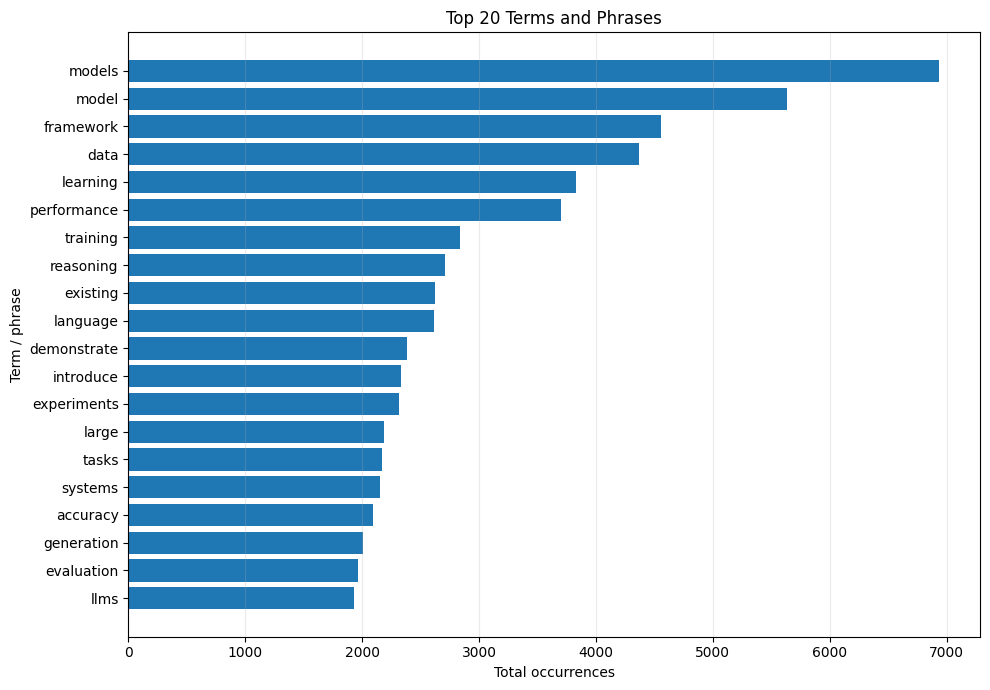

In [6]:
from sklearn.feature_extraction.text import CountVectorizer

DOMAIN_STOP_WORDS = [
    # Optional examples; adjust after inspecting the corpus:
    "paper", "study", "result", "results", "approach", "method", "methods",
    "propose", "proposed", "show", "shows", "using", "based"
]

count_vectorizer = CountVectorizer(
    stop_words=list(set(CountVectorizer(stop_words="english").get_stop_words()) | set(DOMAIN_STOP_WORDS)),
    ngram_range=(1, 2),
    min_df=2 if len(df) >= 20 else 1,
    max_df=0.95,
    max_features=10000,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9-]+\b"
)
X_counts = count_vectorizer.fit_transform(df["abstract_clean"])
terms = count_vectorizer.get_feature_names_out()
frequencies = np.asarray(X_counts.sum(axis=0)).ravel()
term_freq = pd.DataFrame({"term": terms, "frequency": frequencies}).sort_values("frequency", ascending=False)

display(term_freq.head(30).reset_index(drop=True))

plot_terms = term_freq.head(20).sort_values("frequency")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_terms["term"], plot_terms["frequency"])
ax.set(title="Top 20 Terms and Phrases", xlabel="Total occurrences", ylabel="Term / phrase")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

# 7. TF–IDF: distinctive terms by document

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Use the same domain stop words; sklearn also removes standard English stop words.
tfidf_vectorizer = TfidfVectorizer(
    stop_words=list(set(CountVectorizer(stop_words="english").get_stop_words()) | set(DOMAIN_STOP_WORDS)),
    ngram_range=(1, 2),
    min_df=2 if len(df) >= 20 else 1,
    max_df=0.95,
    max_features=15000,
    sublinear_tf=True,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9-]+\b"
)
X_tfidf = tfidf_vectorizer.fit_transform(df["abstract_clean"])
tfidf_terms = tfidf_vectorizer.get_feature_names_out()
mean_tfidf = np.asarray(X_tfidf.mean(axis=0)).ravel()
tfidf_summary = pd.DataFrame({"term": tfidf_terms, "mean_tfidf": mean_tfidf}).sort_values("mean_tfidf", ascending=False)
display(tfidf_summary.head(30).reset_index(drop=True))

# Show the highest-weight terms in a selected abstract.
example_idx = 0
row = X_tfidf[example_idx].toarray().ravel()
top_idx = row.argsort()[-12:][::-1]
print("Example abstract title:", df.iloc[example_idx]["title_analysis"] or "(title unavailable)")
print("Highest TF-IDF terms in this abstract:")
display(pd.DataFrame({"term": tfidf_terms[top_idx], "tfidf": row[top_idx]}))

,term,mean_tfidf
0,models,0.020770
1,model,0.018808
2,framework,0.016660
3,data,0.016402
4,learning,0.015406
5,performance,0.015104
6,training,0.012927
7,language,0.012452
8,existing,0.012241
9,reasoning,0.011706


Example abstract title: Turning the TIDE: Cross-Architecture Distillation for Diffusion Large Language Models
Highest TF-IDF terms in this abstract:


,term,tfidf
0,dllms,0.285060
1,cross-architecture,0.232887
2,teacher,0.196460
3,distillation,0.182832
4,student,0.166309
5,dllm,0.150015
6,parallel decoding,0.143963
7,humaneval,0.137547
8,inverts,0.137547
9,diffusion large,0.135833


# 8. Topic modeling with Latent Dirichlet Allocation (LDA)

,topic,top_terms
0,0,"models, reasoning, language, llms, model, larg..."
1,1,"data, framework, model, learning, performance,..."
2,2,"evaluation, systems, ai, models, data, researc..."
3,3,"neural, networks, training, accuracy, network,..."
4,4,"visual, framework, image, models, video, model..."
5,5,"optimization, learning, problem, algorithm, da..."


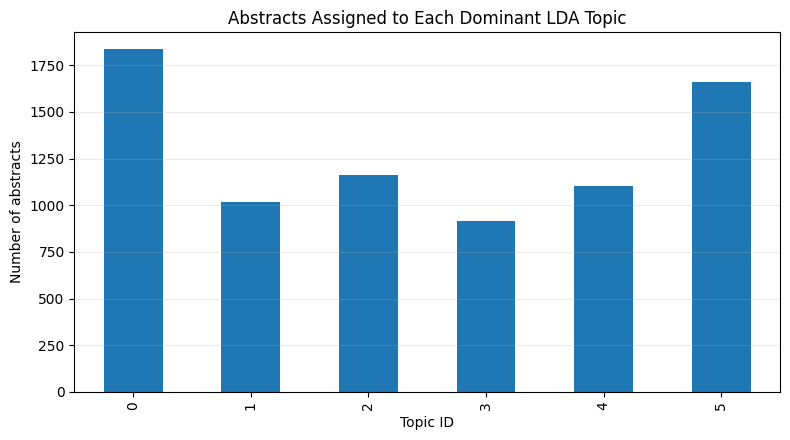


TOPIC 0 — top terms: models, reasoning, language, llms, model, large, language models, large language, llm, retrieval, generation, performance
- SUPERNOVA: Eliciting General Reasoning in LLMs with Reinforcement Learning on Natural Instructions | topic probability=0.996
   Reinforcement Learning with Verifiable Rewards (RLVR) has significantly improved large language model (LLM) reasoning in formal domains such as mathematics and code. Despite these advancements, LLMs still struggle with general reasoning tasks requiring capabilities such as causal inference and temporal understanding. Extending RLVR to general reasoning is fundamentally constrained by the lack of high-quality, verifiable training data that spans d ...
- Do We Still Need GraphRAG? Benchmarking RAG and GraphRAG for Agentic Search Systems | topic probability=0.996
   Retrieval-augmented generation (RAG) and its graph-based extensions (GraphRAG) are effective paradigms for improving large language model (LLM) reasoning by

In [8]:
from sklearn.decomposition import LatentDirichletAllocation

N_TOPICS = 6 if len(df) >= 30 else max(2, min(4, len(df)))
N_TOPICS = min(N_TOPICS, max(2, X_counts.shape[0]))
lda = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=RANDOM_STATE,
    learning_method="batch",
    max_iter=20,
    doc_topic_prior=None,
    topic_word_prior=None
)

doc_topic = lda.fit_transform(X_counts)
df["dominant_topic"] = doc_topic.argmax(axis=1)
df["dominant_topic_probability"] = doc_topic.max(axis=1)

feature_names = count_vectorizer.get_feature_names_out()
topic_rows = []
for topic_id, weights in enumerate(lda.components_):
    top_ids = weights.argsort()[-12:][::-1]
    top_words = [feature_names[i] for i in top_ids]
    topic_rows.append({"topic": topic_id, "top_terms": ", ".join(top_words)})

topic_terms_df = pd.DataFrame(topic_rows)
display(topic_terms_df)

topic_sizes = df["dominant_topic"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
topic_sizes.plot(kind="bar", ax=ax)
ax.set(title="Abstracts Assigned to Each Dominant LDA Topic", xlabel="Topic ID", ylabel="Number of abstracts")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Inspect representative abstracts with the highest probability for each topic.
for topic_id in range(N_TOPICS):
    subset = df[df["dominant_topic"] == topic_id].sort_values("dominant_topic_probability", ascending=False).head(3)
    print(f"\nTOPIC {topic_id} — top terms: {topic_terms_df.loc[topic_terms_df.topic == topic_id, 'top_terms'].iloc[0]}")
    for _, row in subset.iterrows():
        title = row["title_analysis"] or "(title unavailable)"
        abstract = row["abstract_original"]
        print(f"- {title} | topic probability={row['dominant_topic_probability']:.3f}")
        print("  ", abstract[:450].replace("\n", " "), "..." if len(abstract) > 450 else "")

# 9. Optional: abstract similarity search with TF–IDF
This finds abstracts lexically similar to a query. It is useful for quick exploration, but TF–IDF similarity is not the same as deep semantic similarity. For stronger semantic search, use transformer embeddings in a separate extension.

In [9]:
from sklearn.metrics.pairwise import cosine_similarity

# Edit this query to search for a topic of interest.
query = "large language models for scientific reasoning"
query_vec = tfidf_vectorizer.transform([clean_abstract(query)])
similarities = cosine_similarity(query_vec, X_tfidf).ravel()
top_n = min(10, len(df))
nearest = similarities.argsort()[-top_n:][::-1]
search_results = df.iloc[nearest].copy()
search_results["query_similarity"] = similarities[nearest]
cols_to_show = [c for c in ["title_analysis", "publication_year", "query_similarity", "abstract_original"] if c in search_results.columns]
display(search_results[cols_to_show].reset_index(drop=True))

,title_analysis,publication_year,query_similarity,abstract_original
0,PaperMind: Benchmarking Agentic Reasoning and ...,2026,0.325505,Understanding scientific papers requires more ...
1,S1-VL: Scientific Multimodal Reasoning Model w...,2026,0.278841,"We present S1-VL, a multimodal reasoning model..."
2,AI scientists produce results without reasonin...,2026,0.240058,Large language model (LLM)-based systems are i...
3,Cooperative Profiles Predict Multi-Agent LLM T...,2026,0.218505,Multi-agent systems built from teams of large ...
4,MiroThinker-1.7 & H1: Towards Heavy-Duty Resea...,2026,0.198913,"We present MiroThinker-1.7, a new research age..."
5,A Triadic Suffix Tokenization Scheme for Numer...,2026,0.177677,Standard subword tokenization methods fragment...
6,Large language models eroding science understa...,2026,0.168423,This paper is under review in AI and Ethics Th...
7,MeasHalu: Mitigation of Scientific Measurement...,2026,0.163551,The accurate extraction of scientific measurem...
8,Dual-Track CoT: Budget-Aware Stepwise Guidance...,2026,0.146125,Large Language Models (LLMs) solve many reason...
9,Do We Need Bigger Models for Science? Task-Awa...,2026,0.144491,Scientific knowledge discovery increasingly re...


# 10. Evidence-based conclusions generated from this dataset
The next cell creates concise observations using computed values. These are descriptive conclusions about this dataset only—not claims about all AI/ML research. Review the top terms and representative abstracts before assigning scientific meaning to a topic.

In [10]:
print("=" * 78)
print("DATA-DRIVEN SUMMARY")
print("=" * 78)
print(f"Usable abstracts analyzed: {len(df):,}")
print(f"Distinct abstract texts: {df['abstract_original'].nunique():,}")
print(f"Median abstract length: {df['word_count'].median():.1f} words")
print(f"Mean abstract length: {df['word_count'].mean():.1f} words")
print(f"Abstracts shorter than 30 words: {(df['word_count'] < 30).sum():,} ({(df['word_count'] < 30).mean()*100:.1f}%)")

if df["publication_year"].notna().any():
    yr = df["publication_year"].dropna().astype(int)
    print(f"Publication years represented: {yr.min()}–{yr.max()}")
    print(f"Records with parsed year: {len(yr):,} ({len(yr)/len(df)*100:.1f}%)")
else:
    print("Publication-year conclusion: unavailable because no usable year/date values were detected.")

print("\nMost frequent terms/phrases:")
for _, row in term_freq.head(10).iterrows():
    print(f"  • {row['term']}: {int(row['frequency']):,} occurrences")

print("\nLDA topic summary:")
for _, row in topic_terms_df.iterrows():
    count = int((df["dominant_topic"] == row["topic"]).sum())
    share = count / len(df) * 100
    print(f"  • Topic {int(row['topic'])} ({count:,} abstracts; {share:.1f}%): {row['top_terms']}")

if "annual" in globals() and annual is not None and len(annual) > 0:
    print("\nPhrase trends (share of abstracts mentioning phrase):")
    for label in trend_patterns:
        valid = annual[label].dropna()
        if len(valid) >= 2:
            first_year, last_year = int(valid.index.min()), int(valid.index.max())
            print(f"  • {label}: {first_year}={valid.loc[first_year]:.1f}%, {last_year}={valid.loc[last_year]:.1f}%")

print("\nInterpretation cautions:")
print("  • Dataset coverage and collection rules limit generalization beyond this corpus.")
print("  • Keyword mentions do not prove a topic is the paper's main contribution.")
print("  • LDA topics require human interpretation; inspect their representative abstracts.")
print("  • Year comparisons can be affected by incomplete recent-year coverage.")

DATA-DRIVEN SUMMARY
Usable abstracts analyzed: 7,701
Distinct abstract texts: 7,701
Median abstract length: 180.0 words
Mean abstract length: 180.8 words
Abstracts shorter than 30 words: 1 (0.0%)
Publication years represented: 2025–2026
Records with parsed year: 7,701 (100.0%)

Most frequent terms/phrases:
  • models: 6,939 occurrences
  • model: 5,634 occurrences
  • framework: 4,559 occurrences
  • data: 4,365 occurrences
  • learning: 3,831 occurrences
  • performance: 3,701 occurrences
  • training: 2,839 occurrences
  • reasoning: 2,708 occurrences
  • existing: 2,623 occurrences
  • language: 2,618 occurrences

LDA topic summary:
  • Topic 0 (1,835 abstracts; 23.8%): models, reasoning, language, llms, model, large, language models, large language, llm, retrieval, generation, performance
  • Topic 1 (1,020 abstracts; 13.2%): data, framework, model, learning, performance, existing, models, datasets, experiments, demonstrate, features, address
  • Topic 2 (1,162 abstracts; 15.1%): e

# 11. Export cleaned data and analysis tables
These files are saved to the current working directory. In Kaggle, use the notebook's output files panel to download them.

In [11]:
OUTPUT_DIR = Path("nlp_analysis_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

df.to_csv(OUTPUT_DIR / "cleaned_abstracts_with_topics.csv", index=False)
term_freq.to_csv(OUTPUT_DIR / "term_phrase_frequencies.csv", index=False)
tfidf_summary.to_csv(OUTPUT_DIR / "mean_tfidf_terms.csv", index=False)
topic_terms_df.to_csv(OUTPUT_DIR / "lda_topic_terms.csv", index=False)
if "annual" in globals() and annual is not None:
    annual.to_csv(OUTPUT_DIR / "annual_topic_phrase_shares.csv")
print("Saved outputs to:", OUTPUT_DIR.resolve())
for output_file in sorted(OUTPUT_DIR.iterdir()):
    print(" -", output_file.name)

Saved outputs to: /mnt/d/1-ML_and_data_science/8-arxive_Al_ML_papers_abstracts_analysis/nlp_analysis_outputs
 - annual_topic_phrase_shares.csv
 - architecture_training_method_prevalence.csv
 - cleaned_abstracts_with_topics.csv
 - lda_topic_terms.csv
 - mean_tfidf_terms.csv
 - monthly_dataset_coverage.csv
 - monthly_normalized_theme_trends.csv
 - named_model_family_prevalence.csv
 - research_theme_prevalence.csv
 - term_phrase_frequencies.csv


# 12. Advanced NLP: semantic embeddings and semantic search

**Why this section?** TF–IDF compares shared words; sentence embeddings represent semantic meaning, so abstracts using different wording can still be close in vector space.

This section uses `sentence-transformers` with `all-MiniLM-L6-v2`. The first run may download a model and needs internet access unless the model is cached. For reproducibility, record the model name and library versions. Embeddings are computed only when `RUN_EMBEDDINGS = True` to keep the notebook lightweight by default.

**Interpretation caution:** semantic similarity is a screening signal, not proof that two papers make the same scientific claim. Review the nearest abstracts manually.

In [12]:
# Optional dependency: run once in an internet-enabled notebook if needed
# %pip install -q sentence-transformers

RUN_EMBEDDINGS = True  # Change to True to calculate embeddings
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
EMBEDDING_BATCH_SIZE = 64

if RUN_EMBEDDINGS:
    try:
        from sentence_transformers import SentenceTransformer
        from sklearn.metrics.pairwise import cosine_similarity
        from sklearn.cluster import KMeans
        from sklearn.decomposition import PCA

        embedding_texts = (
            df["title"].fillna("").astype(str).str.strip()
            + ". "
            + df["abstract_original"].fillna("").astype(str)
        ).tolist()

        embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)
        embeddings = embedding_model.encode(
            embedding_texts,
            batch_size=EMBEDDING_BATCH_SIZE,
            show_progress_bar=True,
            normalize_embeddings=True
        )
        print("Embedding matrix shape:", embeddings.shape)
        print("Embedding model:", EMBEDDING_MODEL_NAME)

        # Save reusable vectors and document mapping. NPY stores vectors; CSV stores row order.
        OUTPUT_DIR.mkdir(exist_ok=True)
        np.save(OUTPUT_DIR / "semantic_embeddings.npy", embeddings)
        df[["paper_id", "title", "year", "primary_category"]].to_csv(
            OUTPUT_DIR / "embedding_document_index.csv", index=False
        )
    except ImportError as e:
        print("Missing dependency. Install with: %pip install -q sentence-transformers")
        raise
else:
    print("Semantic embeddings skipped. Set RUN_EMBEDDINGS = True to run this section.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/121 [00:00<?, ?it/s]

Embedding matrix shape: (7701, 384)
Embedding model: sentence-transformers/all-MiniLM-L6-v2


## 12.1 Semantic nearest-neighbor search

Edit the query to find abstracts that are semantically related to a research question. This is different from TF–IDF search because it can retrieve conceptually similar papers even when they do not share many exact terms.

In [13]:
if RUN_EMBEDDINGS:
    semantic_query = "methods for improving reasoning and reliability of large language models"
    query_embedding = embedding_model.encode(
        [semantic_query], normalize_embeddings=True
    )
    similarities = (embeddings @ query_embedding[0])
    top_idx = np.argsort(similarities)[::-1][:10]

    semantic_results = df.iloc[top_idx][
        ["paper_id", "title", "year", "primary_category", "abstract_original"]
    ].copy()
    semantic_results["semantic_similarity"] = similarities[top_idx]
    display(semantic_results)
    semantic_results.to_csv(OUTPUT_DIR / "semantic_search_results.csv", index=False)
else:
    print("Enable RUN_EMBEDDINGS above to use semantic search.")

,paper_id,title,year,primary_category,abstract_original,semantic_similarity
4328,2604.14528v1,Dissecting Failure Dynamics in Large Language ...,2026,cs.AI,Large Language Models (LLMs) achieve strong pe...,0.672523
5322,2604.09890v1,Should We be Pedantic About Reasoning Errors i...,2026,cs.CL,Across multiple language pairings (English $\t...,0.650500
5068,2604.11996v1,Filtered Reasoning Score: Evaluating Reasoning...,2026,cs.CL,Should we trust Large Language Models (LLMs) w...,0.650280
1090,2604.23623v1,Tandem: Riding Together with Large and Small L...,2026,cs.AI,Recent advancements in large language models (...,0.647052
4350,2604.15109v2,IUQ: Interrogative Uncertainty Quantification ...,2026,cs.CL,Despite the rapid advancement of Large Languag...,0.638430
4648,2604.14448v1,MARCA: A Checklist-Based Benchmark for Multili...,2026,cs.CL,Large language models (LLMs) are increasingly ...,0.627383
5190,2604.10495v1,Why Don't You Know? Evaluating the Impact of U...,2026,cs.CL,As Large Language Models (LLMs) are increasing...,0.616920
3097,2604.17930v1,Heterogeneity in Formal Linguistic Competence ...,2026,cs.CL,Large Language Models (LLMs) exhibit a puzzlin...,0.606412
3477,2604.17621v1,KnowledgeBerg: Evaluating Systematic Knowledge...,2026,cs.AI,Many real-world questions appear deceptively s...,0.602957
3383,2604.17433v1,Self-Consistency from Only Two Samples: CoT-Po...,2026,cs.CL,Self-consistency (SC) is a popular technique f...,0.601311


## 12.2 Embedding-based clustering (optional)

K-means partitions the embedding space into a chosen number of clusters. Unlike BERTopic, it requires a predefined cluster count and assigns every document to a cluster. Use it as a baseline, not as a claim that the corpus naturally contains exactly *k* topics. Inspect top representative abstracts for each cluster before naming it.

In [14]:
N_SEMANTIC_CLUSTERS = 10

if RUN_EMBEDDINGS:
    from sklearn.cluster import KMeans
    k = min(N_SEMANTIC_CLUSTERS, len(df))
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    df["embedding_cluster"] = kmeans.fit_predict(embeddings)

    # Show the closest examples to each cluster centroid.
    representative_rows = []
    for cluster_id in range(k):
        members = np.flatnonzero(df["embedding_cluster"].to_numpy() == cluster_id)
        if len(members) == 0:
            continue
        center = kmeans.cluster_centers_[cluster_id]
        member_sims = embeddings[members] @ center
        selected = members[np.argsort(member_sims)[::-1][:5]]
        for rank, row_idx in enumerate(selected, start=1):
            representative_rows.append({
                "cluster": cluster_id,
                "rank_in_cluster": rank,
                "paper_id": df.iloc[row_idx].get("paper_id", ""),
                "title": df.iloc[row_idx].get("title", ""),
                "primary_category": df.iloc[row_idx].get("primary_category", ""),
                "abstract": df.iloc[row_idx]["abstract_original"][:700]
            })
    cluster_examples = pd.DataFrame(representative_rows)
    display(cluster_examples.head(25))
    cluster_examples.to_csv(OUTPUT_DIR / "embedding_cluster_representatives.csv", index=False)
else:
    print("Enable RUN_EMBEDDINGS above to run embedding clustering.")

,cluster,rank_in_cluster,paper_id,title,primary_category,abstract
0,0,1,2602.20133v1,AdaEvolve: Adaptive LLM Driven Zeroth-Order Op...,cs.NE,The paradigm of automated program generation i...
1,0,2,2602.04529v1,Landscape-aware Automated Algorithm Design: An...,cs.NE,The advent of Large Language Models (LLMs) has...
2,0,3,2601.12723v2,An Evolutionary Framework for Automatic Optimi...,cs.NE,Optimization benchmarks play a fundamental rol...
3,0,4,2602.23413v2,EvoX: Meta-Evolution for Automated Discovery,cs.LG,Recent work such as AlphaEvolve has shown that...
4,0,5,2601.22542v1,Detect and Act: Automated Dynamic Optimizer th...,cs.NE,Dynamic Optimization Problems (DOPs) are chall...
5,1,1,2604.16379v1,LLMAR: A Tuning-Free Recommendation Framework ...,cs.IR,"Industrial B2B applications (e.g., constructio..."
6,1,2,2604.23734v1,Prism-Reranker: Beyond Relevance Scoring -- Jo...,cs.IR,Modern retrieval pipelines increasingly serve ...
7,1,3,2604.23336v1,Efficient Rationale-based Retrieval: On-policy...,cs.IR,"Unlike traditional fact-based retrieval, ratio..."
8,1,4,2603.20286v1,Rethinking Retrieval-Augmentation as Synthesis...,cs.IR,Retrieval-Augmented Generation (RAG) enables L...
9,1,5,2604.02091v1,Optimizing RAG Rerankers with LLM Feedback via...,cs.CL,Rerankers play a pivotal role in refining retr...


# 13. BERTopic: discover topics from semantic embeddings

BERTopic combines transformer embeddings with dimensionality reduction and density-based clustering, then describes topics using class-based TF–IDF. It can label some documents as outliers rather than forcing every abstract into a topic.

Install if needed (internet-enabled runtime):
```python
%pip install -q bertopic sentence-transformers
```

For reproducibility, note that results can change with package versions, embedding model, and BERTopic parameters. Start with defaults, inspect representative documents, and test stability across settings. The following is optional and does not block the rest of the notebook if BERTopic is not installed.

2026-10-29 13:44:59.318799: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-29 13:45:04.773325: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/121 [00:00<?, ?it/s]

2026-10-29 13:54:37,074 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-29 13:55:24,140 - BERTopic - Dimensionality - Completed ✓
2026-10-29 13:55:24,141 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-29 13:55:24,379 - BERTopic - Cluster - Completed ✓
2026-10-29 13:55:24,383 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-29 13:55:25,354 - BERTopic - Representation - Completed ✓


,Topic,Count,Name,Representation,Representative_Docs
0,-1,2655,-1_the_and_of_to,"[the, and, of, to, in, we, that, for, on, with]",[CoFEE: Reasoning Control for LLM-Based Featur...
1,0,993,0_and_to_the_for,"[and, to, the, for, visual, we, of, in, that, on]",[HMR-Net: Hierarchical Modular Routing for Cro...
2,1,689,1_and_the_to_in,"[and, the, to, in, for, of, control, robot, th...",[RoboAgent: Chaining Basic Capabilities for Em...
3,2,314,2_optimization_the_evolutionary_of,"[optimization, the, evolutionary, of, and, to,...",[Transfer Learning in Bayesian Optimization fo...
4,3,310,3_spiking_neural_networks_neuromorphic,"[spiking, neural, networks, neuromorphic, the,...",[SpikingGamma: Surrogate-Gradient Free and Tem...
5,4,280,4_retrieval_and_rag_the,"[retrieval, and, rag, the, to, query, for, doc...",[Structure Guided Retrieval-Augmented Generati...
6,5,238,5_the_of_we_in,"[the, of, we, in, and, is, for, to, that, this]",[Reflected diffusion models adapt to low-dimen...
7,6,224,6_the_and_attention_to,"[the, and, attention, to, quantization, that, ...",[QSLM: A Performance- and Memory-aware Quantiz...
8,7,199,7_recommendation_user_to_and,"[recommendation, user, to, and, item, recommen...",[Disagreement as Signals: Dual-view Calibratio...
9,8,190,8_segmentation_and_for_the,"[segmentation, and, for, the, of, to, clinical...",[Weighted Knowledge Distillation for Semi-Supe...


,Topic,Count,Name,Representation,Representative_Docs
0,-1,2655,-1_the_and_of_to,"[the, and, of, to, in, we, that, for, on, with]",[CoFEE: Reasoning Control for LLM-Based Featur...


,topic_id,rank,term,c_tf_idf_score
0,0,1,and,0.023737
1,0,2,to,0.020184
2,0,3,the,0.019958
3,0,4,for,0.016133
4,0,5,visual,0.016055
5,0,6,we,0.015906
6,0,7,of,0.015453
7,0,8,in,0.015441
8,0,9,that,0.015204
9,0,10,on,0.014719


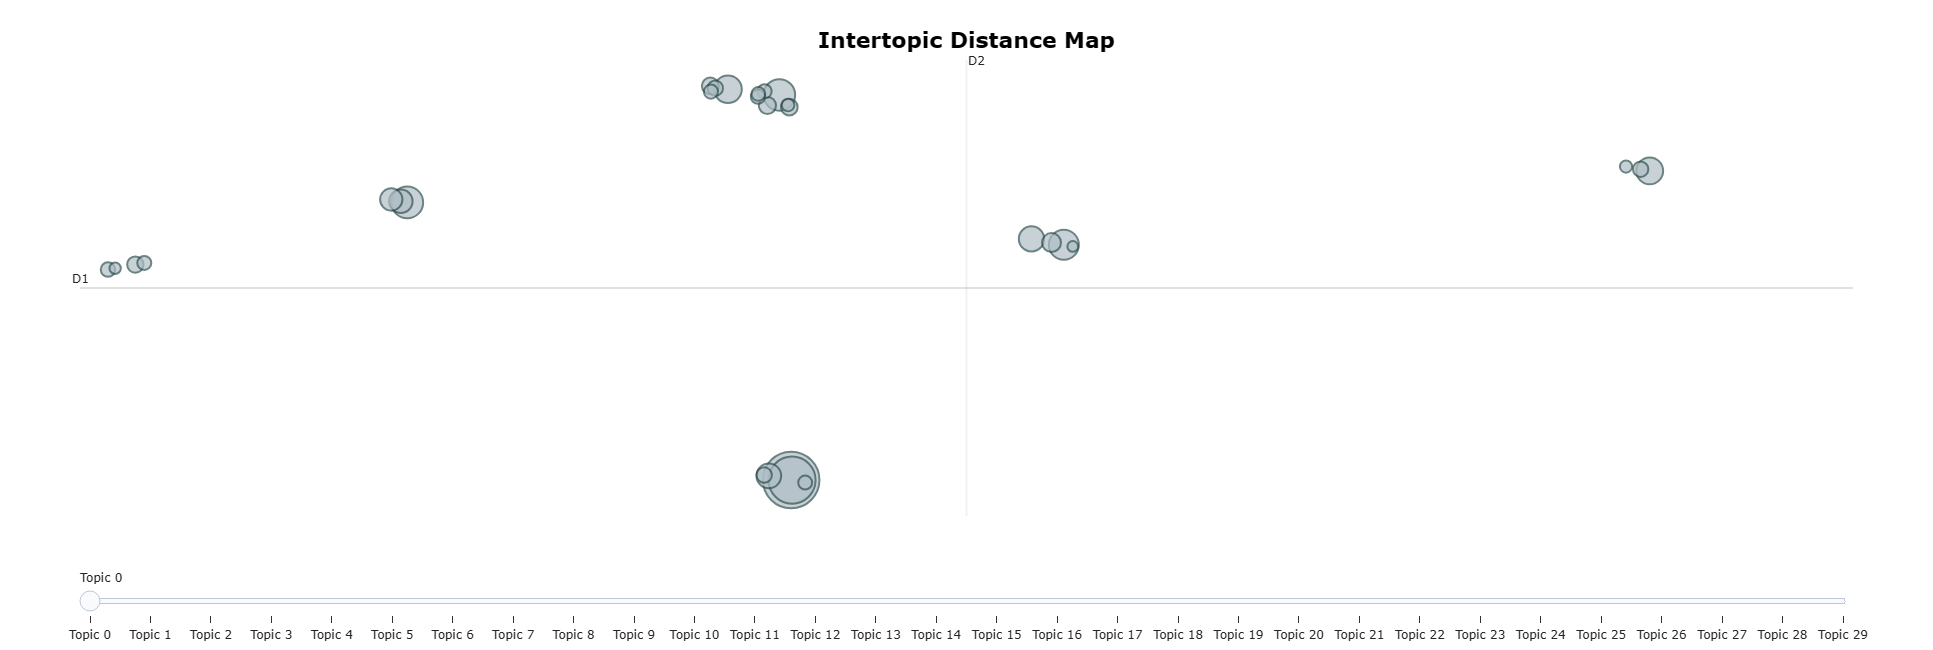

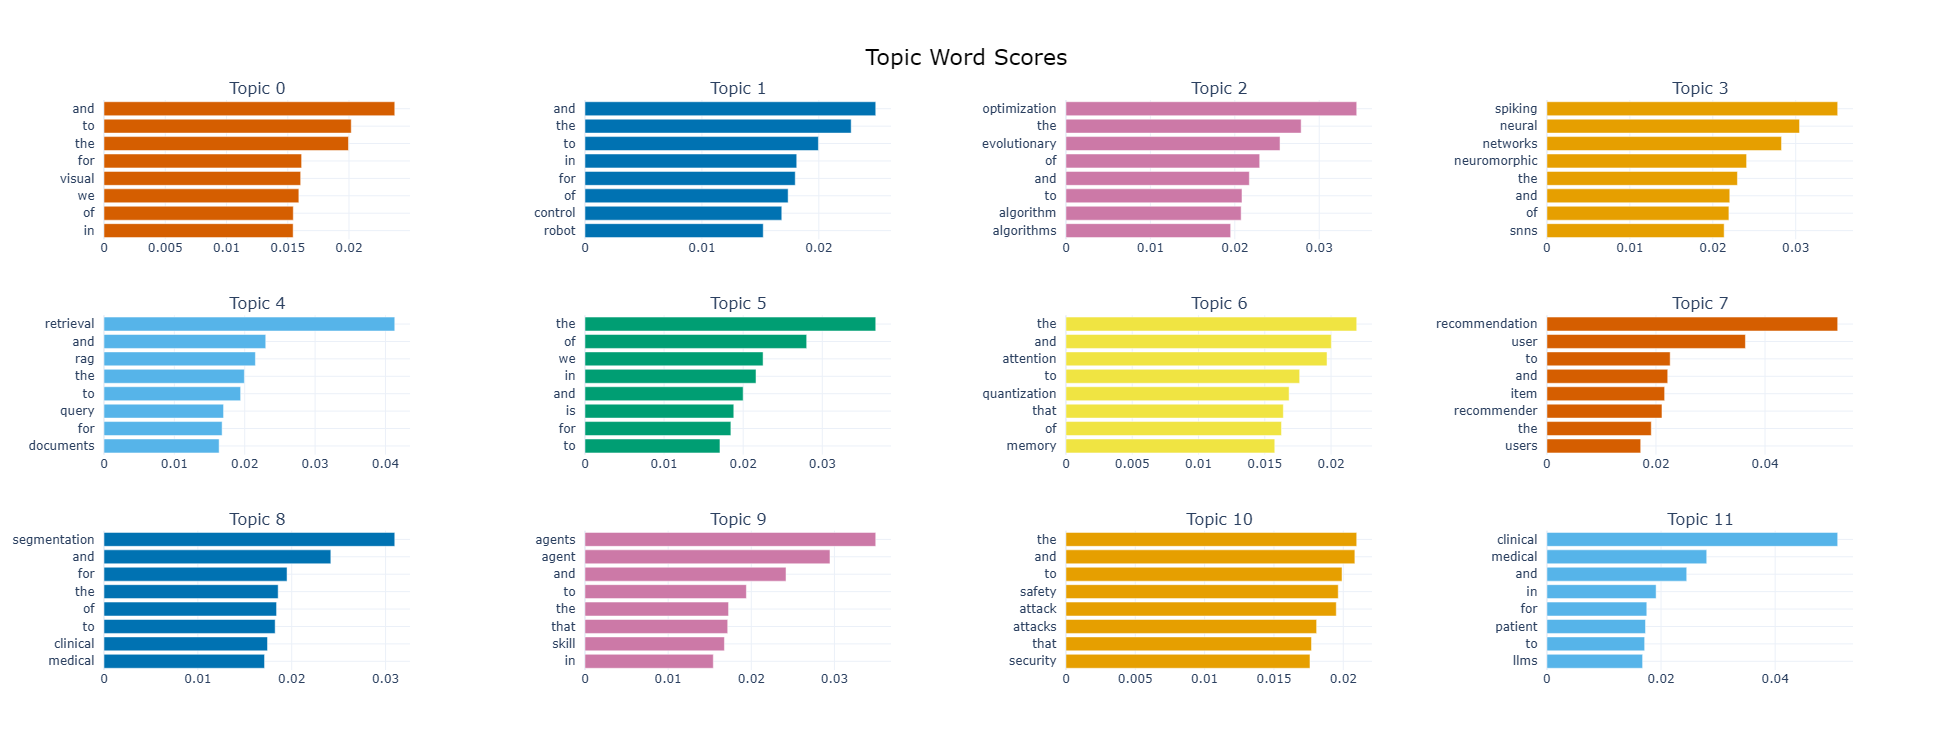

In [15]:
RUN_BERTOPIC = True  # Set True after installing bertopic and sentence-transformers, then run this cell

if RUN_BERTOPIC:
    try:
        from bertopic import BERTopic
        from sentence_transformers import SentenceTransformer

        topic_docs = (
            df["title"].fillna("").astype(str).str.strip()
            + ". "
            + df["abstract_original"].fillna("").astype(str)
        ).tolist()

        topic_embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)
        topic_embeddings = topic_embedding_model.encode(
            topic_docs, batch_size=EMBEDDING_BATCH_SIZE,
            show_progress_bar=True, normalize_embeddings=True
        )

        topic_model = BERTopic(
            embedding_model=None,  # Precomputed embeddings supplied below
            min_topic_size=30,
            calculate_probabilities=False,
            verbose=True
        )
        topic_ids, topic_probs = topic_model.fit_transform(topic_docs, embeddings=topic_embeddings)

        df["bertopic_topic"] = topic_ids
        topic_info = topic_model.get_topic_info()
        display(topic_info.head(30))
        display(topic_model.get_topic_info().head(1))

        topic_info.to_csv(OUTPUT_DIR / "bertopic_topic_info.csv", index=False)
        topic_model.get_document_info(topic_docs).to_csv(
            OUTPUT_DIR / "bertopic_document_topics.csv", index=False
        )

        # Topic keywords and representative papers for manual scientific naming.
        topic_terms_rows = []
        for topic_id in topic_model.get_topics():
            if topic_id == -1:
                continue  # -1 denotes outliers
            topic_terms = topic_model.get_topic(topic_id) or []
            for rank, (term, score) in enumerate(topic_terms[:15], start=1):
                topic_terms_rows.append({
                    "topic_id": topic_id, "rank": rank,
                    "term": term, "c_tf_idf_score": score
                })
        topic_terms_df = pd.DataFrame(topic_terms_rows)
        display(topic_terms_df.head(40))
        topic_terms_df.to_csv(OUTPUT_DIR / "bertopic_topic_terms.csv", index=False)

        try:
            fig = topic_model.visualize_topics()
            fig.show()
        except Exception as viz_error:
            print("BERTopic topic visualization unavailable in this environment:", viz_error)

        try:
            fig = topic_model.visualize_barchart(top_n_topics=12, n_words=8)
            fig.show()
        except Exception as viz_error:
            print("BERTopic bar chart unavailable in this environment:", viz_error)

    except ImportError:
        print("BERTopic dependencies are missing. Run: %pip install -q bertopic sentence-transformers")
        raise
else:
    print("BERTopic skipped. Install dependencies, then set RUN_BERTOPIC = True.")

> **Note on the BERTopic output above.** The default BERTopic vectorizer keeps English stop words, so several topic labels are dominated by words such as "and", "the" and "to" (for example topics 0, 1, 5 and 25) and are not interpretable from keywords alone. 2,655 of 7,701 papers (34.5%) are outliers (topic -1). Interpret topics through their representative papers, or re-fit with `CountVectorizer(stop_words="english")` passed as `vectorizer_model`.

## 13.1 Topic validation checklist

Do not treat automatically generated topic labels as ground truth. Before using topics in a paper:

1. Read at least 10–20 representative abstracts per major topic.
2. Check whether the top terms and representative documents describe one coherent theme.
3. Report the number and percentage of outlier documents (BERTopic topic `-1`).
4. Test at least two `min_topic_size` settings and, if feasible, a second embedding model.
5. Compare the topic solution with the existing arXiv primary-category labels, while noting that categories are broad and may not align one-to-one with semantic topics.
6. Keep the full parameter settings and package versions with the exported results.

# 14. Scientific interpretation and research-paper planning

## 14.1 Dataset facts observed from the supplied CSV

The supplied file contains **7,701 rows and 26 columns**. In the current CSV, `paper_id`, `title`, `abstract`, `year`, and `primary_category` are present; the four latter fields have no missing values in the inspected file. All 7,701 paper IDs and abstract strings are unique in this snapshot.

Descriptive statistics calculated directly from this CSV:

- **Publication date coverage:** 27 September 2025 to 29 April 2026 (`submitted_date`).
- **Year counts:** 416 records labeled 2025 and 7,285 labeled 2026. This imbalance is expected to be strongly affected by the dataset's collection window; it must not be interpreted as annual growth.
- **Most represented primary categories:** `cs.CV` (1,418; 18.4%), `cs.LG` (1,392; 18.1%), `cs.CL` (1,119; 14.5%), `cs.RO` (633; 8.2%), `cs.AI` (555; 7.2%), `cs.NE` (511; 6.6%), `cs.IR` (456; 5.9%), and `stat.ML` (398; 5.2%).
- **Authors per paper:** mean 5.12; median 4.
- **Abstract length:** mean approximately 180 whitespace-delimited words (this is a simple token count, not a linguistic tokenization measure).
- **Journal-reference flag:** 3.2% of records have `has_journal_ref = 1`; **DOI flag:** 4.4% have `has_doi = 1`. These are fields in this dataset and may be incomplete; they are not a complete measure of publication status.

These are descriptive facts about this CSV snapshot, not a census of all arXiv AI/ML research. The data's time window is less than eight months, so claims about long-term trends, emergence, or annual growth are not supported without a longer, consistently collected dataset.

## 14.2 Candidate research questions

The following are research questions to test—not findings that can be claimed before the analyses run.

**RQ1. What semantic themes characterize the sampled arXiv AI/ML literature from September 2025 to April 2026?**  
Method: BERTopic with transformer embeddings; report topic prevalence, representative abstracts, and outlier rate. Validate topics through manual reading.

**RQ2. How do semantic topics differ across arXiv primary categories?**  
Method: cross-tabulate validated topics with `primary_category`; use normalized proportions and a chi-square test only if expected cell counts are adequate. Since papers can belong to multiple categories (`all_categories`), clarify whether the analysis uses only primary category or multi-label categories.

**RQ3. Which themes are shared across computer vision, language, learning, robotics, and statistical machine learning, and which are category-specific?**  
Method: compare topic distributions across categories; use normalized topic proportions and examples of cross-category papers. Avoid equating shared embedding proximity with causal influence.

**RQ4. Which research themes appear in the title/abstract corpus, and how robust are they to modeling choices?**  
Method: compare LDA and BERTopic; vary topic count / `min_topic_size`; compare topic coherence and human interpretability. Do not select a model based only on the most appealing labels.

**RQ5. Can semantic search improve retrieval of papers relevant to a specific scientific question compared with TF–IDF search?**  
Method: create a small, manually judged query–document relevance set and compare precision@k or nDCG@k. Without human relevance judgments, demonstrate retrieval examples but do not claim that semantic search is objectively better.

**RQ6. Are there descriptive differences in metadata (e.g., author count, DOI/journal-reference flags) across topics?**  
Method: summarize distributions by topic and report uncertainty. These associations are not measures of paper quality, impact, or rigor.

## 14.3 Recommended analysis and reporting plan

1. **Corpus description:** document how the dataset was collected, inclusion/exclusion rules, retrieval date, source URL, and whether it is a complete query result or a sampled subset.
2. **Data audit:** check duplicate versions of the same arXiv paper. `paper_id` values with version suffixes (for example, `v1`) may represent versions; consider grouping by the base arXiv identifier for sensitivity analysis rather than deleting versions blindly.
3. **Baseline NLP:** keyword/n-gram counts, TF–IDF, and LDA as transparent baselines.
4. **Semantic NLP:** sentence embeddings and BERTopic, with model name, package versions, parameters, random seed where applicable, and hardware/runtime details.
5. **Validation:** manually review representative abstracts; test stability across settings; compare with arXiv categories as a weak external reference, not as definitive ground truth.
6. **Bias and limitations:** acknowledge arXiv coverage bias, category imbalance, short date range, metadata incompleteness, English-language assumptions, and the fact that abstracts omit methods/results details found in full papers.
7. **Reproducibility:** export cleaned records, topic assignments, topic terms, representative papers, model settings, and generated plots. Avoid publishing raw full abstracts unless the applicable terms permit redistribution; IDs and links are often sufficient.
8. **Claims:** distinguish descriptive prevalence from scientific importance. A frequent topic is not necessarily more novel, impactful, or methodologically sound.

## 14.4 Draft conclusion template (fill with computed results)

> This study examined a time-bounded collection of arXiv AI/ML paper metadata and abstracts using lexical analysis, topic modeling, and transformer-based semantic representations. The corpus contained 7,701 records dated 27 September 2025–29 April 2026, with the largest primary-category groups being computer vision (`cs.CV`), machine learning (`cs.LG`), and computation and language (`cs.CL`). These counts describe the sampled dataset rather than the full research landscape. BERTopic and embedding-based clustering can reveal candidate semantic themes, but final topic names and interpretations require inspection of representative abstracts and robustness checks. Because the collection spans less than one year and is heavily concentrated in 2026, it cannot establish long-term publication trends. Future work should use a consistently collected multi-year corpus and human-validated topic labels to test whether the themes persist and how they vary across categories.

**Important:** Replace this draft with results from the executed topic models. Add the actual number of topics, topic prevalence, representative terms, validation procedure, and any statistical tests only after they have been computed and checked.

In [16]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("nlp_analysis_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Prepare title + abstract text
title_series = (
    df[TITLE_COL].fillna("").astype(str)
    if TITLE_COL and TITLE_COL in df.columns
    else pd.Series("", index=df.index)
)

abstract_series = df["abstract_original"].fillna("").astype(str)

df["title_abstract_text"] = (
    title_series + " " + abstract_series
).str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

print("Papers analyzed:", len(df))
print("Text fields prepared.")

Papers analyzed: 7701
Text fields prepared.


,research_theme,paper_count,paper_share_pct
0,Evaluation and benchmarks,3086,40.07
1,Large language models,2053,26.66
2,Reasoning and inference,1220,15.84
3,AI safety and alignment,730,9.48
4,Multimodal AI,640,8.31
5,AI agents,427,5.54
6,Robotics and embodied AI,342,4.44
7,Retrieval-augmented generation,210,2.73
8,Recommendation systems,164,2.13
9,Synthetic data,136,1.77


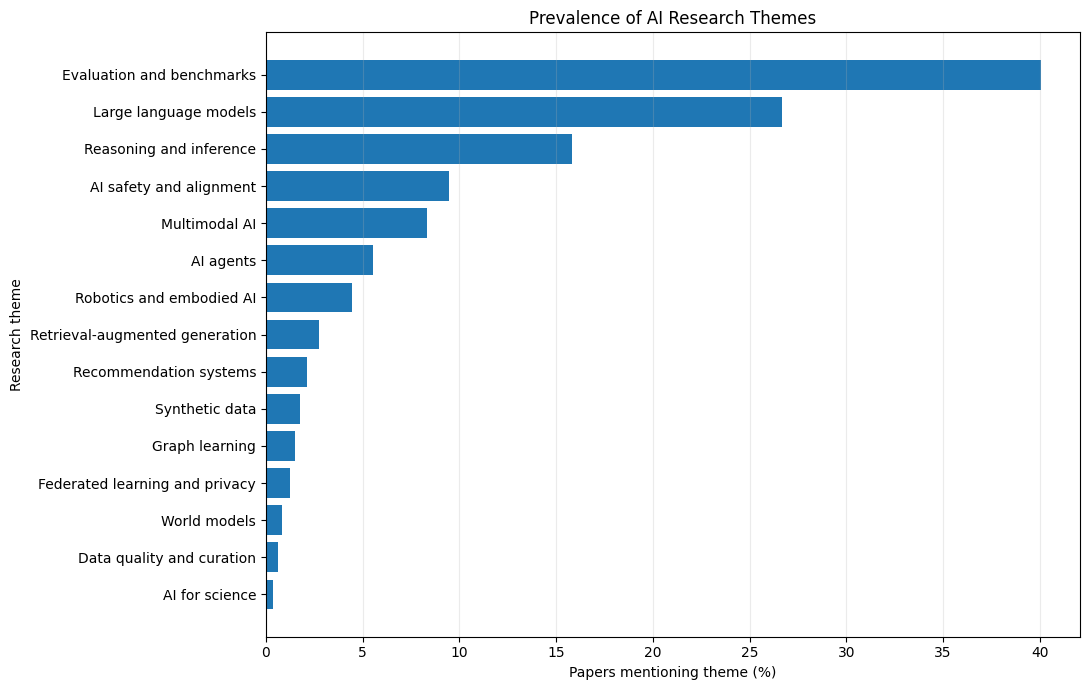

In [17]:
research_theme_patterns = {
    "Large language models": r"\blarge language models?\b|\bllms?\b",
    "Reasoning and inference": r"\breasoning\b|chain[- ]of[- ]thought|inference[- ]time scaling",
    "AI agents": r"\bagentic\b|\bautonomous agents?\b|\bai agents?\b|\bllm agents?\b",
    "Retrieval-augmented generation": r"\bretrieval[- ]augmented generation\b|\brag\b",
    "Multimodal AI": r"\bmultimodal\b|\bmulti[- ]modal\b",
    "AI safety and alignment": r"\bai safety\b|\bllm safety\b|\balignment\b|\bred[- ]teaming\b",
    "Evaluation and benchmarks": r"\bevaluation\b|\bbenchmarks?\b|\bevaluating\b",
    "Synthetic data": r"\bsynthetic data\b|\bdata synthesis\b",
    "Data quality and curation": r"\bdata curation\b|\bdata quality\b|\bdataset quality\b",
    "Robotics and embodied AI": r"\brobotics?\b|\bembodied ai\b|\bembodied intelligence\b",
    "World models": r"\bworld models?\b",
    "AI for science": r"\bai for science\b|\bmachine learning for science\b|\bscientific discovery\b",
    "Recommendation systems": r"\brecommender systems?\b|\brecommendation systems?\b|\bpersonalization\b",
    "Federated learning and privacy": r"\bfederated learning\b|\bdifferential privacy\b|\bprivacy-preserving\b",
    "Graph learning": r"\bgraph neural networks?\b|\bgnns?\b|\bgraph learning\b",
}

def calculate_prevalence(text, patterns, label_name):
    results = []

    for label, pattern in patterns.items():
        matched = text.str.contains(
            pattern, regex=True, case=False, na=False
        )

        results.append({
            label_name: label,
            "paper_count": int(matched.sum()),
            "paper_share_pct": round(matched.mean() * 100, 2),
        })

    return pd.DataFrame(results).sort_values(
        "paper_count", ascending=False
    ).reset_index(drop=True)


research_theme_summary = calculate_prevalence(
    df["title_abstract_text"],
    research_theme_patterns,
    "research_theme"
)

display(research_theme_summary)

research_theme_summary.to_csv(
    OUTPUT_DIR / "research_theme_prevalence.csv",
    index=False
)

plot_df = research_theme_summary.sort_values("paper_share_pct")

plt.figure(figsize=(11, 7))
plt.barh(plot_df["research_theme"], plot_df["paper_share_pct"])
plt.xlabel("Papers mentioning theme (%)")
plt.ylabel("Research theme")
plt.title("Prevalence of AI Research Themes")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

,model_family,paper_count,paper_share_pct
0,GPT / OpenAI,197,2.56
1,Qwen,196,2.55
2,Llama,132,1.71
3,Gemini,100,1.30
4,Claude / Anthropic,83,1.08
5,Gemma,60,0.78
6,BERT / RoBERTa,53,0.69
7,DeepSeek,50,0.65
8,Mistral / Mixtral,29,0.38
9,Phi models,15,0.19


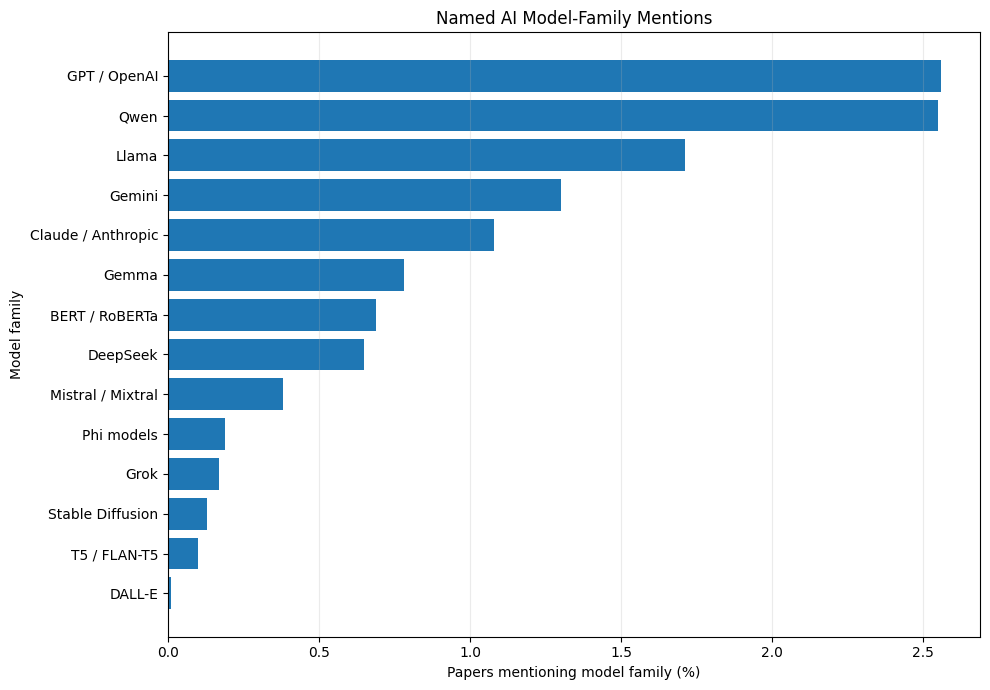

In [18]:
model_family_patterns = {
    "GPT / OpenAI": r"\bgpt[- ]?(?:3|3\.5|4|4o|4\.1|4\.5|5)\b|\bopenai\b",
    "Llama": r"\bllama(?:[- ]?[1234])?(?:\.\d+)?\b",
    "Gemini": r"\bgemini(?:\s*(?:1\.5|2\.0|2\.5|pro|flash|ultra))?\b",
    "Claude / Anthropic": r"\bclaude(?:\s*(?:2|3|3\.5|3\.7|4|sonnet|opus|haiku))?\b|\banthropic\b",
    "Qwen": r"\bqwen(?:[- ]?\d+(?:\.\d+)?)?\b|\bqwq\b",
    "DeepSeek": r"\bdeepseek(?:[- ]?(?:v\d+|r\d+|coder|math|vl|moe))?\b",
    "Gemma": r"\bgemma(?:[- ]?\d+(?:\.\d+)?)?\b",
    "Mistral / Mixtral": r"\bmistral\b|\bmixtral\b",
    "Phi models": r"\bphi[- ]?[1234](?:\.\d+)?\b|\bphi[- ]?mini\b",
    "Grok": r"\bgrok(?:[- ]?\d+(?:\.\d+)?)?\b",
    "Stable Diffusion": r"\bstable diffusion\b",
    "DALL-E": r"\bdall[- ]?e\b|\bdalle\b",
    "BERT / RoBERTa": r"\bbert\b|\broberta\b",
    "T5 / FLAN-T5": r"\bflan[- ]?t5\b|\bt5\b",
}

model_family_summary = calculate_prevalence(
    df["title_abstract_text"],
    model_family_patterns,
    "model_family"
)

display(model_family_summary)

model_family_summary.to_csv(
    OUTPUT_DIR / "named_model_family_prevalence.csv",
    index=False
)

plot_df = model_family_summary.sort_values("paper_share_pct")

plt.figure(figsize=(10, 7))
plt.barh(plot_df["model_family"], plot_df["paper_share_pct"])
plt.xlabel("Papers mentioning model family (%)")
plt.ylabel("Model family")
plt.title("Named AI Model-Family Mentions")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

,method,paper_count,paper_share_pct
0,Reinforcement learning,567,7.36
1,Transformer architecture,540,7.01
2,Vision-language models,312,4.05
3,Pruning and sparsity,257,3.34
4,Diffusion models,198,2.57
5,Synthetic-data training,136,1.77
6,Quantization,131,1.70
7,LoRA / PEFT,121,1.57
8,Chain-of-thought,121,1.57
9,Graph neural networks,109,1.42


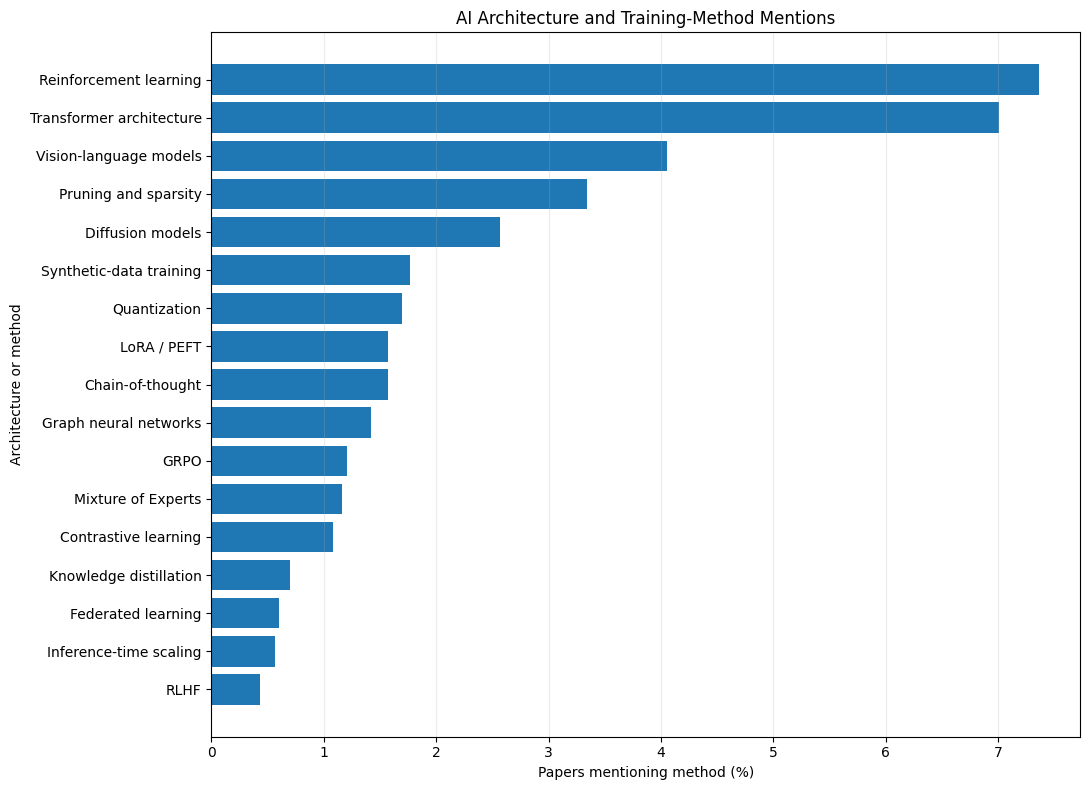

In [19]:
method_patterns = {
    "Transformer architecture": r"\btransformers?\b|\bself[- ]attention\b",
    "Mixture of Experts": r"\bmixture[- ]of[- ]experts\b|\bmoe\b",
    "LoRA / PEFT": r"\blora\b|\bqlora\b|\bparameter[- ]efficient fine[- ]tuning\b|\bpeft\b",
    "GRPO": r"\bgrpo\b|\bgroup relative policy optimization\b",
    "RLHF": r"\brlhf\b|\breinforcement learning from human feedback\b",
    "Reinforcement learning": r"\breinforcement learning\b|\bpolicy optimization\b",
    "Diffusion models": r"\bdiffusion models?\b|\bdenoising diffusion\b",
    "Vision-language models": r"\bvision[- ]language models?\b|\bvlms?\b",
    "Graph neural networks": r"\bgraph neural networks?\b|\bgnns?\b",
    "Knowledge distillation": r"\bknowledge distillation\b|\bmodel distillation\b",
    "Quantization": r"\bquantization\b|\bquantisation\b|\b4[- ]bit\b|\b8[- ]bit\b",
    "Pruning and sparsity": r"\bpruning\b|\bsparsity\b|\bsparse models?\b",
    "Inference-time scaling": r"\binference[- ]time scaling\b|\btest[- ]time scaling\b|\btest[- ]time compute\b",
    "Chain-of-thought": r"\bchain[- ]of[- ]thought\b|\bcot prompting\b",
    "Synthetic-data training": r"\bsynthetic data\b|\bdata synthesis\b",
    "Federated learning": r"\bfederated learning\b",
    "Contrastive learning": r"\bcontrastive learning\b|\bcontrastive loss\b",
}

method_summary = calculate_prevalence(
    df["title_abstract_text"],
    method_patterns,
    "method"
)

display(method_summary)

method_summary.to_csv(
    OUTPUT_DIR / "architecture_training_method_prevalence.csv",
    index=False
)

plot_df = method_summary.sort_values("paper_share_pct")

plt.figure(figsize=(11, 8))
plt.barh(plot_df["method"], plot_df["paper_share_pct"])
plt.xlabel("Papers mentioning method (%)")
plt.ylabel("Architecture or method")
plt.title("AI Architecture and Training-Method Mentions")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

In [20]:
if "bertopic_topic" in df.columns and df["bertopic_topic"].notna().any():

    topic_ids = df["bertopic_topic"].astype(int)
    total_docs = len(df)

    outlier_count = int((topic_ids == -1).sum())

    print(f"Total documents: {total_docs:,}")
    print(
        f"Outliers: {outlier_count:,} "
        f"({outlier_count / total_docs * 100:.2f}%)"
    )

    topic_rows = []

    for topic_id, group in df.groupby(topic_ids):
        terms = ""

        if topic_id != -1 and "topic_model" in globals():
            topic_terms = topic_model.get_topic(int(topic_id)) or []
            terms = ", ".join(term for term, score in topic_terms[:10])

        topic_rows.append({
            "topic_id": int(topic_id),
            "topic_label": "Outliers" if topic_id == -1 else f"Topic {topic_id}",
            "paper_count": len(group),
            "paper_share_pct": round(len(group) / total_docs * 100, 2),
            "top_terms": terms,
        })

    bertopic_summary = pd.DataFrame(topic_rows).sort_values(
        "paper_count", ascending=False
    )

    display(bertopic_summary)

    # Inspect representative abstracts for each topic.
    representative_rows = []

    for topic_id in sorted(topic_ids.unique()):
        if topic_id == -1:
            continue

        group = df.loc[topic_ids == topic_id]
        selected_indices = []

        if "topic_model" in globals():
            try:
                representative_docs = (
                    topic_model.get_representative_docs(int(topic_id)) or []
                )

                selected_indices = group.index[
                    group["abstract_original"].isin(representative_docs)
                ].tolist()
            except Exception:
                selected_indices = []

        if not selected_indices:
            selected_indices = group.index[:3].tolist()

        for idx in selected_indices[:3]:
            row = df.loc[idx]

            representative_rows.append({
                "topic_id": int(topic_id),
                "title": row.get("title_analysis", ""),
                "paper_id": row.get("paper_id", ""),
                "primary_category": row.get("primary_category", ""),
                "abstract_excerpt": str(row["abstract_original"])[:600],
            })

    bertopic_representatives = pd.DataFrame(representative_rows)

    display(bertopic_representatives)

    bertopic_summary.to_csv(
        OUTPUT_DIR / "bertopic_topic_summary.csv", index=False
    )

    bertopic_representatives.to_csv(
        OUTPUT_DIR / "bertopic_representative_papers.csv", index=False
    )

else:
    print("BERTopic results are unavailable.")
    print("Run the BERTopic model first, then rerun this cell.")

Total documents: 7,701
Outliers: 2,655 (34.48%)


,topic_id,topic_label,paper_count,paper_share_pct,top_terms
0,-1,Outliers,2655,34.48,
1,0,Topic 0,993,12.89,"and, to, the, for, visual, we, of, in, that, on"
2,1,Topic 1,689,8.95,"and, the, to, in, for, of, control, robot, tha..."
3,2,Topic 2,314,4.08,"optimization, the, evolutionary, of, and, to, ..."
4,3,Topic 3,310,4.03,"spiking, neural, networks, neuromorphic, the, ..."
5,4,Topic 4,280,3.64,"retrieval, and, rag, the, to, query, for, docu..."
6,5,Topic 5,238,3.09,"the, of, we, in, and, is, for, to, that, this"
7,6,Topic 6,224,2.91,"the, and, attention, to, quantization, that, o..."
8,7,Topic 7,199,2.58,"recommendation, user, to, and, item, recommend..."
9,8,Topic 8,190,2.47,"segmentation, and, for, the, of, to, clinical,..."


,topic_id,title,paper_id,primary_category,abstract_excerpt
0,0,AirZoo: A Unified Large-Scale Dataset for Grou...,2604.26567v1,cs.CV,Despite the rapid progress in data-driven 3D v...
1,0,"DenseStep2M: A Scalable, Training-Free Pipelin...",2604.26565v1,cs.CV,Long-term video understanding requires interpr...
2,0,3D-LENS: A 3D Lifting-based Elevated Novel-vie...,2604.26520v1,cs.CV,Aerial-Ground Re-Identification (AG-ReID) is c...
3,1,3D Generation for Embodied AI and Robotic Simu...,2604.26509v1,cs.RO,Embodied AI and robotic systems increasingly d...
4,1,Three-Step Nav: A Hierarchical Global-Local Pl...,2604.26946v1,cs.CV,Breakthrough progress in vision-based navigati...
...,...,...,...,...,...
85,28,Mutual Forcing: Dual-Mode Self-Evolution for F...,2604.25819v1,cs.CV,"In this work, we propose Mutual Forcing, a fra..."
86,28,Walking Through Uncertainty: An Empirical Stud...,2604.25591v1,eess.AS,Recent audio-aware large language models (ALLM...
87,29,Hierarchical Long-Term Semantic Memory for Lin...,2604.26197v1,cs.IR,Large Language Model (LLM) agents are increasi...
88,29,StratMem-Bench: Evaluating Strategic Memory Us...,2604.26243v1,cs.CL,Achieving realistic human-like conversation fo...


Date column: submitted_date
Date range: 2025-09-27 00:00:00+00:00 to 2026-04-29 00:00:00+00:00


,paper_count,dataset_share_pct,month_over_month_change_pct
month,,,
2025-09,25,0.32,NaN
2025-10,139,1.80,456.00
2025-11,125,1.62,-10.07
2025-12,127,1.65,1.60
2026-01,149,1.93,17.32
2026-02,136,1.77,-8.72
2026-03,969,12.58,612.50
2026-04,6031,78.31,522.39


,Large language models,Reasoning and inference,AI agents,Retrieval-augmented generation,Multimodal AI,AI safety and alignment,Evaluation and benchmarks,Synthetic data,Data quality and curation,Robotics and embodied AI,World models,AI for science,Recommendation systems,Federated learning and privacy,Graph learning,Transformers,Diffusion models,Reinforcement learning,LoRA / PEFT,GRPO
month,,,,,,,,,,,,,,,,,,,,
2025-09,28.00,16.00,0.00,0.00,4.00,4.00,16.00,0.00,0.00,4.00,0.00,0.00,0.00,0.00,4.00,12.00,0.00,12.00,0.00,0.00
2025-10,16.55,3.60,0.72,0.00,2.16,7.19,23.74,1.44,0.00,4.32,0.72,0.72,0.00,1.44,2.16,12.23,1.44,6.47,0.72,0.00
2025-11,12.00,4.00,0.80,1.60,1.60,4.80,34.40,0.00,0.00,0.80,0.00,0.00,0.80,1.60,0.80,8.00,2.40,7.20,0.80,0.00
2025-12,8.66,0.79,2.36,0.00,4.72,2.36,31.50,0.79,0.79,0.00,2.36,0.79,0.00,0.00,4.72,4.72,0.79,7.09,0.79,0.00
2026-01,14.77,4.70,2.01,0.67,4.70,4.03,34.23,0.00,0.00,4.03,0.00,0.00,0.00,0.00,0.67,8.05,0.00,8.05,0.00,0.00
2026-02,11.76,5.15,0.74,0.74,2.94,5.15,29.41,0.00,0.00,1.47,0.74,0.74,0.74,0.00,2.21,5.15,1.47,5.15,2.21,0.00
2026-03,19.92,9.08,4.75,4.95,4.44,7.02,32.20,2.48,0.21,0.62,0.00,0.72,5.16,1.34,1.03,5.37,2.58,5.47,0.83,0.72
2026-04,29.28,18.29,6.17,2.62,9.52,10.43,42.50,1.81,0.76,5.31,0.95,0.30,1.86,1.33,1.53,7.18,2.74,7.71,1.77,1.43


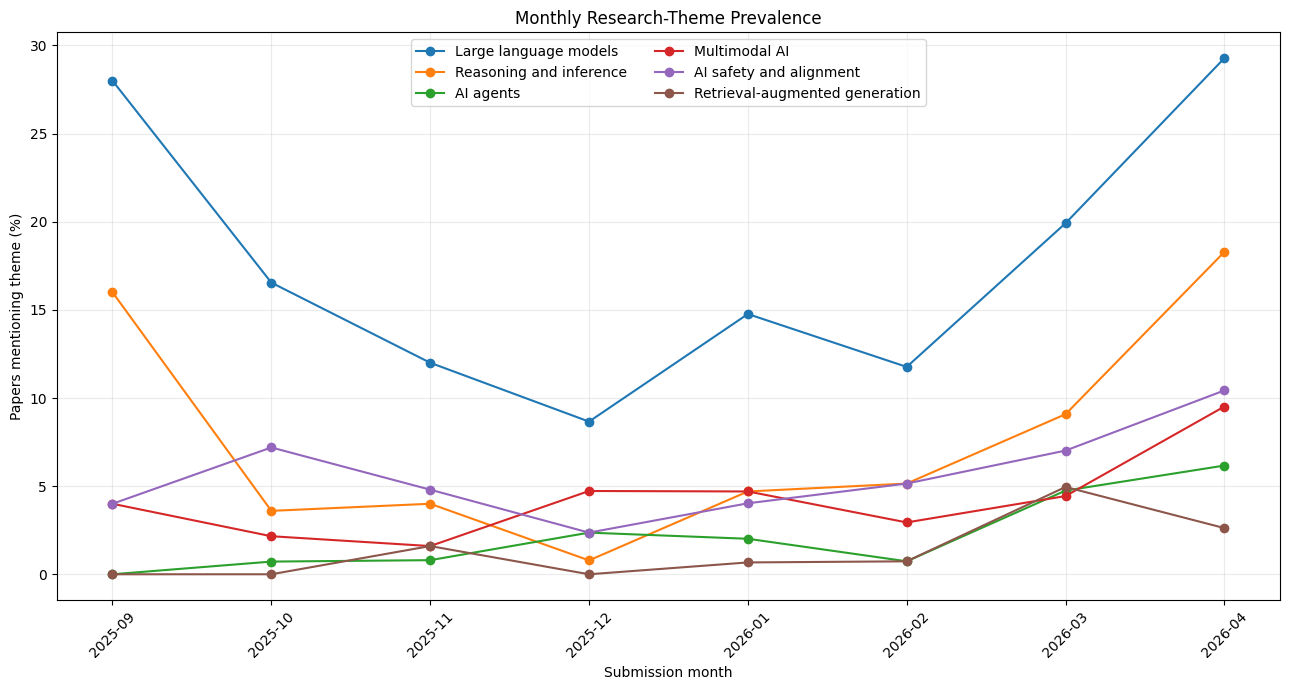

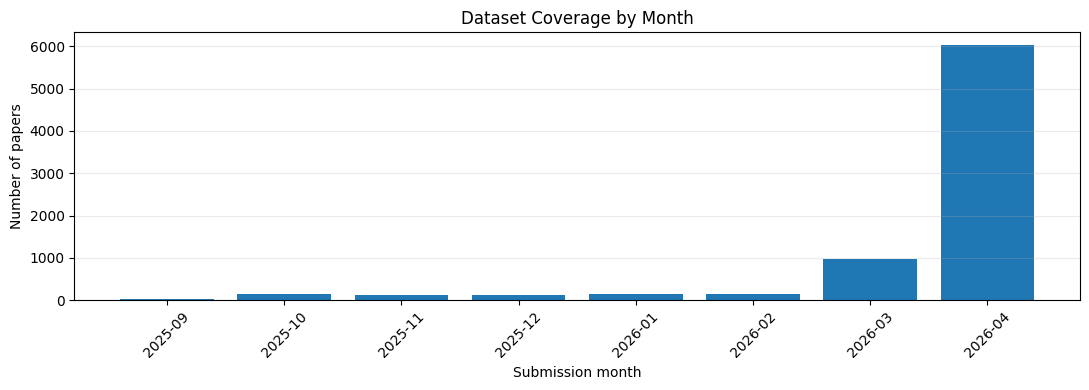

LIMITATION: fewer than 12 monthly periods are available. Long-term trends cannot be established.


In [21]:
date_candidates = [
    "submitted_date",
    "submission_date",
    "published_date",
    "publication_date",
    "created_date",
    "date",
]

date_col = next(
    (col for col in date_candidates if col in df.columns),
    None
)

if date_col is not None:

    dates = pd.to_datetime(df[date_col], errors="coerce", utc=True)

    temporal_df = df.loc[dates.notna()].copy()
    temporal_df["analysis_date"] = dates.loc[dates.notna()]
    temporal_df["month"] = (
        temporal_df["analysis_date"].dt.to_period("M").astype(str)
    )

    # Dataset coverage by month
    coverage = (
        temporal_df.groupby("month")
        .size()
        .rename("paper_count")
        .to_frame()
    )

    coverage["dataset_share_pct"] = (
        coverage["paper_count"] / len(df) * 100
    )

    coverage["month_over_month_change_pct"] = (
        coverage["paper_count"].pct_change() * 100
    )

    print("Date column:", date_col)
    print("Date range:",
          temporal_df["analysis_date"].min(),
          "to",
          temporal_df["analysis_date"].max())

    display(coverage.round(2))

    # Theme patterns for monthly prevalence
    monthly_patterns = {
        **research_theme_patterns,
        "Transformers": method_patterns["Transformer architecture"],
        "Diffusion models": method_patterns["Diffusion models"],
        "Reinforcement learning": method_patterns["Reinforcement learning"],
        "LoRA / PEFT": method_patterns["LoRA / PEFT"],
        "GRPO": method_patterns["GRPO"],
    }

    for label, pattern in monthly_patterns.items():
        temporal_df[label] = temporal_df[
            "title_abstract_text"
        ].str.contains(pattern, case=False, regex=True, na=False)

    # Each value is the percentage of papers in that month mentioning a theme.
    monthly_share = (
        temporal_df.groupby("month")[list(monthly_patterns.keys())].mean()
        * 100
    )

    display(monthly_share.round(2))

    # Plot selected themes
    plot_df = monthly_share[
        [
            "Large language models",
            "Reasoning and inference",
            "AI agents",
            "Multimodal AI",
            "AI safety and alignment",
            "Retrieval-augmented generation",
        ]
    ]

    plt.figure(figsize=(13, 7))

    for theme in plot_df.columns:
        plt.plot(
            plot_df.index,
            plot_df[theme],
            marker="o",
            label=theme
        )

    plt.xlabel("Submission month")
    plt.ylabel("Papers mentioning theme (%)")
    plt.title("Monthly Research-Theme Prevalence")
    plt.xticks(rotation=45)
    plt.legend(ncol=2)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    # Plot monthly dataset coverage
    plt.figure(figsize=(11, 4))
    plt.bar(coverage.index, coverage["paper_count"])
    plt.xlabel("Submission month")
    plt.ylabel("Number of papers")
    plt.title("Dataset Coverage by Month")
    plt.xticks(rotation=45)
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

    median_count = coverage["paper_count"].median()

    if median_count > 0 and coverage["paper_count"].max() > 3 * median_count:
        print(
            "WARNING: monthly coverage is highly uneven. "
            "Do not interpret raw counts as research growth."
        )

    if len(coverage) < 12:
        print(
            "LIMITATION: fewer than 12 monthly periods are available. "
            "Long-term trends cannot be established."
        )

    coverage.to_csv(OUTPUT_DIR / "monthly_dataset_coverage.csv")
    monthly_share.to_csv(OUTPUT_DIR / "monthly_normalized_theme_trends.csv")

else:
    print("No suitable date column was found.")

In [22]:
research_theme_summary.to_csv(
    OUTPUT_DIR / "research_theme_prevalence.csv", index=False
)

model_family_summary.to_csv(
    OUTPUT_DIR / "named_model_family_prevalence.csv", index=False
)

method_summary.to_csv(
    OUTPUT_DIR / "architecture_training_method_prevalence.csv",
    index=False
)

print("Analysis files saved to:", OUTPUT_DIR.resolve())

for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name)

Analysis files saved to: /mnt/d/1-ML_and_data_science/8-arxive_Al_ML_papers_abstracts_analysis/nlp_analysis_outputs
annual_topic_phrase_shares.csv
architecture_training_method_prevalence.csv
bertopic_document_topics.csv
bertopic_representative_papers.csv
bertopic_topic_info.csv
bertopic_topic_summary.csv
bertopic_topic_terms.csv
cleaned_abstracts_with_topics.csv
embedding_cluster_representatives.csv
embedding_document_index.csv
lda_topic_terms.csv
mean_tfidf_terms.csv
monthly_dataset_coverage.csv
monthly_normalized_theme_trends.csv
named_model_family_prevalence.csv
research_theme_prevalence.csv
semantic_embeddings.npy
semantic_search_results.csv
term_phrase_frequencies.csv


In [23]:
print("SCIENTIFIC INTERPRETATION")
print("=" * 60)

print("\nTop research themes:")
display(research_theme_summary.head(5))

print("\nTop model families:")
display(model_family_summary.head(5))

print("\nTop architecture and training methods:")
display(method_summary.head(5))

print("""
Interpretation guidelines:

1. Mention frequency is not evidence of research quality or novelty.
2. A model name in an abstract does not prove that the model was evaluated.
3. Curated regex patterns may produce false positives and false negatives.
4. BERTopic topics require inspection of representative abstracts.
5. Monthly percentages must be interpreted alongside dataset coverage.
6. A short or uneven collection window cannot establish long-term trends.
7. For publication, document the collection query, date range, inclusion
   criteria, alias patterns, model settings, and validation procedure.
""")

SCIENTIFIC INTERPRETATION

Top research themes:


,research_theme,paper_count,paper_share_pct
0,Evaluation and benchmarks,3086,40.07
1,Large language models,2053,26.66
2,Reasoning and inference,1220,15.84
3,AI safety and alignment,730,9.48
4,Multimodal AI,640,8.31



Top model families:


,model_family,paper_count,paper_share_pct
0,GPT / OpenAI,197,2.56
1,Qwen,196,2.55
2,Llama,132,1.71
3,Gemini,100,1.30
4,Claude / Anthropic,83,1.08



Top architecture and training methods:


,method,paper_count,paper_share_pct
0,Reinforcement learning,567,7.36
1,Transformer architecture,540,7.01
2,Vision-language models,312,4.05
3,Pruning and sparsity,257,3.34
4,Diffusion models,198,2.57



Interpretation guidelines:

1. Mention frequency is not evidence of research quality or novelty.
2. A model name in an abstract does not prove that the model was evaluated.
3. Curated regex patterns may produce false positives and false negatives.
4. BERTopic topics require inspection of representative abstracts.
5. Monthly percentages must be interpreted alongside dataset coverage.
6. A short or uneven collection window cannot establish long-term trends.
7. For publication, document the collection query, date range, inclusion
   criteria, alias patterns, model settings, and validation procedure.

